# Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Activation 


## Q3.1 : 
### Import Data


In [2]:
df=pd.read_excel('housing.xlsx')
df


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


### Q3.1.a : the missing data


For the missing data , i concluded that it should be replaced with the median of the whole column


In [3]:
#calculate the number of empty cells
missing_counts = df.isnull().sum()

print("NA counts for each column:")
print(missing_counts)


NA counts for each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [4]:
#check a sample of the dataframe
df.iloc[-1]


longitude             -121.24
latitude                39.37
housing_median_age       16.0
total_rooms            2785.0
total_bedrooms          616.0
population             1387.0
households              530.0
median_income          2.3886
median_house_value    89400.0
ocean_proximity        INLAND
Name: 20639, dtype: object

In [5]:
median = df['total_bedrooms'].median()
median


np.float64(435.0)

In [6]:
df['total_bedrooms'].fillna(median, inplace=True)
missing_counts2= df.isnull().sum()

print("NA counts for each column:")
print(missing_counts,missing_counts2)


NA counts for each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64 longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


C:\Users\user\AppData\Local\Temp\ipykernel_18024\759384086.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['total_bedrooms'].fillna(median, inplace=True)


### Q3.1.c : convert any column that contains text (strings) into a column that contains only numbers.


In [7]:
df.columns


Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [8]:
for col_name in df.columns:
    column_data = df[col_name]
    print(f"{col_name} is : {column_data.dtype}")


longitude is : float64
latitude is : float64
housing_median_age is : float64
total_rooms is : float64
total_bedrooms is : float64
population is : float64
households is : float64
median_income is : float64
median_house_value is : float64
ocean_proximity is : object


In [9]:
df['ocean_proximity'].value_counts()


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [ ]:
# This will show all the unique text values
print(df['ocean_proximity'].unique())
# Create custom distance mapping
distance_map = {
    'NEAR OCEAN': 1,  # Closest
    'NEAR BAY':   2,  # Also very close
    'ISLAND':     3,  # Surrounded by water
    '<1H OCEAN':  4,  # Further away
    'INLAND':     5   # Farthest
}
#  .map() to replace the text with numbers
df['distance_from_ocean'] = df['ocean_proximity'].map(distance_map)

# check the result
print(df[['ocean_proximity', 'distance_from_ocean']].head())


['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']
  ocean_proximity  distance_from_ocean
0        NEAR BAY                    2
1        NEAR BAY                    2
2        NEAR BAY                    2
3        NEAR BAY                    2
4        NEAR BAY                    2


In [11]:
df=df.drop('ocean_proximity', axis=1) #deleting the string column from the dataframe
df


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,distance_from_ocean
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,2
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,2
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,2
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,2
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,2
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,5
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,5
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,5
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,5


#### saving the cleaned data in a new excel file


In [12]:
df.to_excel('ocean dist encoded data.xlsx',index=False)# so the index of the datas (0,1,2,..) wil not be saved as a seprate col
print ('cleaned ocean data saved')


cleaned ocean data saved


### Q3.1.b : now we have to remove the outliers:
to do this , we use the InterQuartile Range (IQR)
we define lower_bound and upper_bound,


lower_bound: we go below Q1 by 1.5 times the "spread" (IQR). Any house price below this value is considered a low-end outlier.

upper_bound: we go above Q3 by 1.5 times the "spread" (IQR). Any house price above this value is considered a high-end outlier.

#### NOTE :WHY 1.5 ?

The 1.5 is a standard statistical rule of thumb for identifying mild outliers.


In [13]:
#target col
price_col='median_house_value'

print(f"Original shape with outliers: {df.shape}")#F_STRING TO DIRECTLY PUT VAR into text string

#calculate the Q1 & Q3 (the first 0.25 and 0.75 of data)
Q1=df[price_col].quantile(0.25)
Q3=df[price_col].quantile(0.75)

#now IQR
IQR=Q3-Q1

low_lim=Q1 - 1.5 * IQR
up_lim=Q3 + 1.5 * IQR

#overwrite original df with a new DataFrame
df = df[(df[price_col] >= low_lim) & (df[price_col] <= up_lim)]
#see the result:
print(f"New shape after removing outliers: {df.shape}")

df.to_excel('removed outliers data.xlsx',index=False)# so the index of the datas (0,1,2,..) wil not be saved as a seprate col
print ('removed outliers data saved')


Original shape with outliers: (20640, 10)
New shape after removing outliers: (19569, 10)
removed outliers data saved


## split the data for training and testing.
According to Table 2 in PDF, the required ratio for "Train, Validation, Test" is 80%-10%-10%. 

We'll separate the data into features (X) and the target (y).

Since the train_test_split function can only split data into two sets at a time (a "train" and a "test" set), we have to use it twice to get three sets.


We'll do a first split: 80% for training (X_train) and 20% into a temporary set.

We'll split that 20% temporary set exactly in half (50/50), which gives 10% for validation (X_val) and 10% for testing (X_test).


### further about train_test_split(X, y, test_size=0.2, random_state=42):
out put : four vectors, matrices 
input : the feature set X, The target set Y, the ratio of the whole to go to the second set , the radom num generator seed (for shuffling the data we need random num, if no seed , every time the shuffle will differ, seed an be any integer,e.g. 34,99,21..)


In [14]:
from sklearn.model_selection import train_test_split

#we separate features (X) from the target (y)

# X is everything EXCEPT 'median_house_value'
X = df.drop('median_house_value', axis=1)

# y is ONLY 'median_house_value'
y = df['median_house_value']

# Split data into 80% training and 20% temporary (for validation + test)
# test_size=0.2 means 20% goes to X_temp/y_temp
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Split the 20% temporary set in half (0.5 * 20% = 10% of total)
# This gives us our 10% validation and 10% test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# 4. Print the shapes to confirm the split
print(f"Total original samples: {len(df)}")
print(f"---")
print(f"X_train shape: {X_train.shape}  (~80%)")
print(f"y_train shape: {y_train.shape}")
print(f"---")
print(f"X_val shape: {X_val.shape}    (~10%)")
print(f"y_val shape: {y_val.shape}")
print(f"---")
print(f"X_test shape: {X_test.shape}   (~10%)")
print(f"y_test shape: {y_test.shape}")


Total original samples: 19569
---
X_train shape: (15655, 9)  (~80%)
y_train shape: (15655,)
---
X_val shape: (1957, 9)    (~10%)
y_val shape: (1957,)
---
X_test shape: (1957, 9)   (~10%)
y_test shape: (1957,)


## Q3.2: Implementation of a simple neural network.

We will build the exact model described in Table 1 :

A Linear (Dense) layer with 8 units.

A ReLU activation.

A final Linear (Dense) layer with 1 unit (for the price).


In [15]:
# We need to know the number of input features (columns) in X_train = 9 in our case

#X_train.shape is (rows, columns). For example, (15655, 9).
#X_train.shape[1] grabs the second number, 9.

input_size = X_train.shape[1]

print(f"Number of input features (input_size): {input_size}")

# 1. Define the model

model_simple = Sequential()# Sequential() creates an empty, "sequential" neural network. 
# This means we are going to build it in a simple stack, adding layers
# one on top of the other.
# Right now, model_simple is just an empty shell.


# 2. Add the layers from Table 1
# Layer 1: Linear (Dense)(fully connected,every input is connected to every neuron), In=input_size, Out=8 (with 8 nuerons)
model_simple.add(Dense(8, input_dim=input_size, activation='relu'))#relu activation :"If result : negative, report 0. If: positive, report the number.

# Layer 3: Linear (Dense), In=8, Out=1(one neuron), 
# we only want one out come, the houseprice so we have to get the 8 feature related numbers, make one single decision.
# We don't add an activation, as this is a regression (predicting a raw number)
model_simple.add(Dense(1))#no relu, cause We want the network to be able to output any value it thinks is correct.

# 3. Compile the model (from Table 2)
# We set the learning rate for Adam to 0.1 as specified(makeing a BIG correction every step)
# We set the loss to 'mse' (Mean Squared Error)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.1)

model_simple.compile(optimizer=optimizer, loss='mean_squared_error')

# 4. Report the number of parameters
print("\n--- Simple Model Summary ---")
model_simple.summary()


Number of input features (input_size): 9

--- Simple Model Summary ---


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89 (356.00 B)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

## report the number of parameters: 89 parameters (the total number of weights and biases that were gonna tune)
First Layer (dense_2): 80 parameters

9 input features, 8 neurons.

Each input is connected to each neuron, so: 9 (inputs) * 8 (neurons) = 72 weights.

Each of the 8 neurons also gets 1 bias (a single "offset" knob).

Total: 72 (weights) + 8 (biases) = 80 parameters.

Second Layer (dense_3): 9 parameters

8 inputs from the 8 neurons of the layer before it.

It has 1 output neuron (for the final price).

Each input is connected to the neuron: 8 (inputs) * 1 (neuron) = 8 weights.

This 1 neuron also gets 1 bias.

Total: 8 (weights) + 1 (bias) = 9 parameters.

Grand Total: 80 + 9 = 89 parameters.


## Q3.3:Training the simple neural network

This process involves two main parts:

Running the training (.fit()).


Plotting the results to see how it learned.


### Q3.3.1:The training
We will save the results of the training (like the loss at each epoch) into a variable called history


In [ ]:
print("Starting the training process...")

# Start the training
history = model_simple.fit(
    X_train,
    y_train,
    
    epochs=60,#epochs=60: This tells the model to loop through the entire 80% 
    #training dataset 60 times,specified inassignment. Each full pass is one "epoch."

    batch_size=64,#This tells the model how to loop through the data.
    #Instead of looking at all ~15,000 training samples at once, it will look at a "batch" 
    # of 64 samples, make a guess, get graded (by the loss function), 
    #and get fixed (by the optimizer). Then it moves to the next 64 samples.
    validation_data=(X_val, y_val),
    
    verbose=1#verbose=1: This just tells Keras to print a progress bar for each epoch.
)

print("Training finished.")


Starting the training process...
Epoch 1/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 17711972352.0000 - val_loss: 10119062528.0000
Epoch 2/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 8526295552.0000 - val_loss: 7933740544.0000
Epoch 3/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 7890460160.0000 - val_loss: 7652769280.0000
Epoch 4/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 7634215936.0000 - val_loss: 7332998144.0000
Epoch 5/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 7327446528.0000 - val_loss: 7140335104.0000
Epoch 6/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 7066989568.0000 - val_loss: 6831440384.0000
Epoch 7/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6734349312.0000 - val_loss: 6654583808.0000
Epoch 8/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6496968704.0000 - val_loss: 6305501184.0000
Epoch 9/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6238182400.0000 - val_loss: 6137260032.0000
Epoch 10/60
245/245 ━━━━━━━━━

### Q3.3.2:The plotting
The history contains our training log, we can plot it:


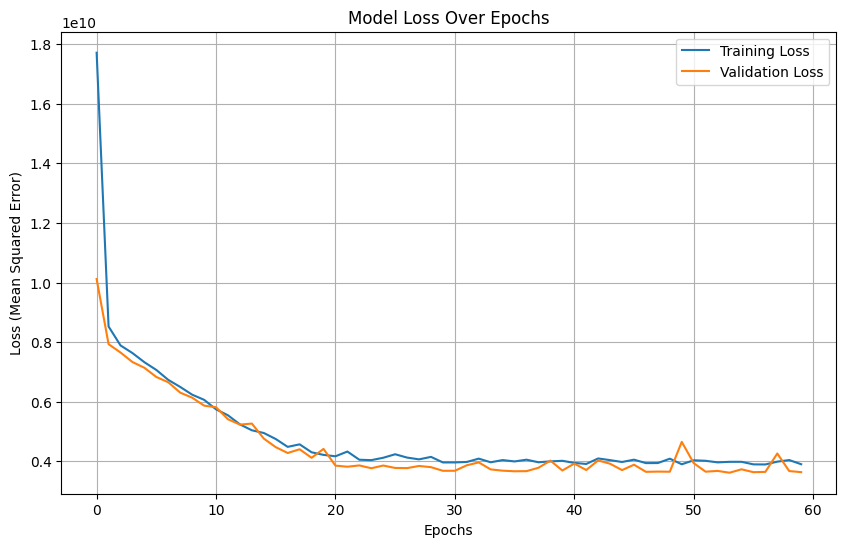

In [17]:
plt.figure(figsize=(10, 6))

# Plot the training loss
plt.plot(history.history['loss'], label='Training Loss')

# Plot the validation loss
plt.plot(history.history['val_loss'], label='Validation Loss')
#history.history['val_loss'] gets the list of loss values from the training data for all 60 epochs.

# Add labels and a title
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Mean Squared Error)')
plt.legend()
plt.grid(True)
plt.show()


### analysis:
1. both lines going down -> the model is learning


2. the validation loss is noisy-> probably because of high learning rate 0.1


3. gap between validation loss and training loss-> model is slightly overfitting


4. the validation loss at the end is usually < training loss: 
    probably because The two loss values are not calculated at the same time.
    
    Training Loss (loss): This value, for each epoch, is the average of the loss from all the mini-batches within that epoch. The model's weights are being updated after every batch. This means the loss from the first batch (when the model is "dumber") is averaged with the loss from the last batch (when the model is "smarter").

    Validation Loss (val_loss): This value is calculated only once at the very end of the epoch, using the model's final, updated weights from that epoch.


### Q3.3.3:Calculating the metrics

#### "explain and report the metrics MSE, MAE, R2, and RMSE."
 we have to implement these metrics ourselves in form of functions(cant use sklearn.metrics) :
 in all of them , we need the y_predicted and y_true as inputs:

* MSE:  mean of (y_predicted- y_true): mean((y_predicted- y_true)^2)
* RMSE: sqrt of MSE : sqrt(mean((y_predicted- y_true)^2))
* MAE:  mean of the |y_predicted- y_true|
* R2:   1 - (Sum of Squared Errors / Total Sum of Squares)=1- sum ((y_predicted- y_true)^2) / sum((y_true - mean_true)^2)


In [18]:
#extracting the y_predicted:

y_pred_train = model_simple.predict(X_train)
y_pred_val = model_simple.predict(X_val)
#get the test data tested in our model
y_pred_test = model_simple.predict(X_test)


def calc_mse(y_true, y_pred):
    return np.mean(np.square(y_pred - y_true))

def calc_rmse(y_true, y_pred):
    return np.sqrt(np.mean(np.square(y_pred - y_true)))

def calc_mae(y_true, y_pred):
    return np.mean(np.abs(y_pred - y_true))

def calc_r2(y_true, y_pred):
    ss_res = np.sum(np.square(y_true - y_pred)) # Sum of squared residuals
    ss_tot = np.sum(np.square(y_true - np.mean(y_true))) # Total sum of squares
    return 1 - (ss_res / ss_tot)


# i encountered error in subtracting y_true,y_pred 
# because one is pandas 1D series, the other is 2D numpy series:

# Convert pandas Series to numpy array with .values
# Squeeze 2D prediction array to 1D with .squeeze()
y_true_train = y_train.values
y_true_val = y_val.values
y_true_test = y_test.values

y_pred_train_1d = y_pred_train.squeeze()
y_pred_val_1d = y_pred_val.squeeze()
y_pred_test_1d = y_pred_test.squeeze()

#calculate+ report for all three sets

print("--- Simple Model Metrics ---")

# Training Set
print("\nTraining Set:")
print(f"  MSE:  {calc_mse(y_true_train, y_pred_train_1d):.2f}")
print(f"  RMSE: {calc_rmse(y_true_train, y_pred_train_1d):.2f}")
print(f"  MAE:  {calc_mae(y_true_train, y_pred_train_1d):.2f}")
print(f"  R2:   {calc_r2(y_true_train, y_pred_train_1d):.4f}")

# Validation Set
print("\nValidation Set:")
print(f"  MSE:  {calc_mse(y_true_val, y_pred_val_1d):.2f}")
print(f"  RMSE: {calc_rmse(y_true_val, y_pred_val_1d):.2f}")
print(f"  MAE:  {calc_mae(y_true_val, y_pred_val_1d):.2f}")
print(f"  R2:   {calc_r2(y_true_val, y_pred_val_1d):.4f}")

# Test Set
print("\nTest Set:")
print(f"  MSE:  {calc_mse(y_true_test, y_pred_test_1d):.2f}")
print(f"  RMSE: {calc_rmse(y_true_test, y_pred_test_1d):.2f}")
print(f"  MAE:  {calc_mae(y_true_test, y_pred_test_1d):.2f}")
print(f"  R2:   {calc_r2(y_true_test, y_pred_test_1d):.4f}")


490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 662us/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 859us/step
--- Simple Model Metrics ---

Training Set:
  MSE:  3782897591.57
  RMSE: 61505.26
  MAE:  45518.84
  R2:   0.5831

Validation Set:
  MSE:  3638557886.13
  RMSE: 60320.46
  MAE:  44841.51
  R2:   0.5943

Test Set:
  MSE:  3602108533.30
  RMSE: 60017.57
  MAE:  45293.61
  R2:   0.6217


## Q3.4:Design and training of a more complex neural network

goal :build a better model that can achieve an R2 score of at least 0.7. 
R2 was ~0.59, meaning it was underfitting ,too simple to get the patterns.

we will make 3 major changes :

1. use more layers (deeper)
2. use more neurons (wider)
3. use smaller, hence more stable learning rate (much less than 0.1)

we should use the same number of epochs and report the number of parameters


### Q3.4.1:Defining the complex model:
design:

* layer1: Dense, with 128 neurons
* layer2: Dense , with 64 neurons (hidden layer 1)
* layer3: Dense , with 32 neurons (hidden layer 2)
* layer4: Dense , with 16 neurons (hidden layer 3)
* layer5: Dense , with 8 neurons (hidden layer 4)
* layer6(output): Dense , with 1 neuron (to make the final value prediction)

**  learning rate : 0.001 (100 times smaller than 0.1)


In [19]:
input_size = X_train.shape[1]
model_cmplx = Sequential()

model_cmplx.add(Dense(128,input_dim=input_size, activation='relu'))
model_cmplx.add(Dense(64,activation='relu'))
model_cmplx.add(Dense(32,activation='relu'))
model_cmplx.add(Dense(16,activation ='relu'))
model_cmplx.add(Dense(8,activation ='relu'))
model_cmplx.add(Dense(1))

optimizer_cmplx=tf.keras.optimizers.Adam(learning_rate=0.001)
model_cmplx.compile(optimizer=optimizer_cmplx, loss='mean_squared_error')

print("\n--- Complex Model Summary ---")
model_cmplx.summary()



--- Complex Model Summary ---


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
from sklearn.preprocessing import StandardScaler

# Define StandardScaler
# The scaler must only 'learn' the mean and standard deviation from the training data.
scaler = StandardScaler()

# Fit and Transform the TRAINING data
X_train_scaled = scaler.fit_transform(X_train)

#Transform the Validation and Test sets using the mean/std 
# learned from the TRAINING set
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Input features standardized.")


Input features standardized.


### Q3.4.2. Training the Complex Model:


In [21]:
print("\nStarting the COMPLEX model training process...")

history_complex = model_cmplx.fit(
    X_train_scaled,
    y_train,
    epochs=60,
    batch_size=64,
    validation_data=(X_val_scaled, y_val),
    verbose=1 # Set to 1 to see progress, 0 to hide it
)

print("Complex model training finished.")



Starting the COMPLEX model training process...
Epoch 1/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 36586049536.0000 - val_loss: 10361466880.0000
Epoch 2/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7260756992.0000 - val_loss: 5943376896.0000
Epoch 3/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5203414528.0000 - val_loss: 4768789504.0000
Epoch 4/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4394028544.0000 - val_loss: 4087263488.0000
Epoch 5/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3934964736.0000 - val_loss: 3690115328.0000
Epoch 6/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3671133440.0000 - val_loss: 3468607488.0000
Epoch 7/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3528289536.0000 - val_loss: 3342109696.0000
Epoch 8/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3445136384.0000 - val_loss: 3271362816.0000
Epoch 9/60
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3397363712.0000 - val_loss: 3237241344.0000
Epoch 10/60
24

### Q3.4.3. Plotting the New Loss


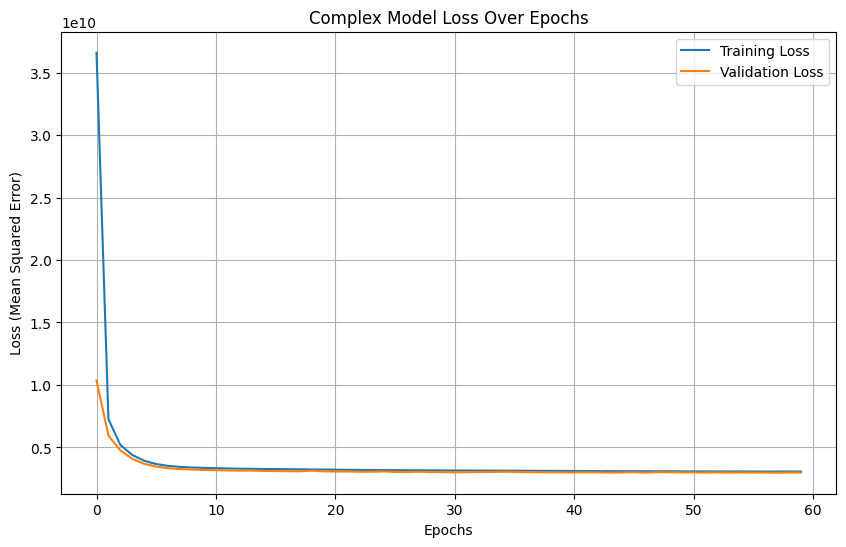

In [22]:
# Plot the complex model's loss
plt.figure(figsize=(10, 6))
plt.plot(history_complex.history['loss'], label='Training Loss')
plt.plot(history_complex.history['val_loss'], label='Validation Loss')
plt.title('Complex Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Mean Squared Error)')
plt.legend()
plt.grid(True)
plt.show()


### Q3.4.4. Calculating Metrics for the Complex Model
with the exact same metrics


In [23]:
# 1. Get predictions from the new model
y_pred_train_c = model_cmplx.predict(X_train_scaled)
y_pred_val_c = model_cmplx.predict(X_val_scaled)
y_pred_test_c = model_cmplx.predict(X_test_scaled)

# 2. Squeeze arrays to 1D for our functions
y_pred_train_c_1d = y_pred_train_c.squeeze()
y_pred_val_c_1d = y_pred_val_c.squeeze()
y_pred_test_c_1d = y_pred_test_c.squeeze()

# (We re-use y_true_train, y_true_val, y_true_test from before)

# 3. Calculate and report metrics
print("--- Complex Model Metrics ---")

# Training Set
print("\nTraining Set:")
print(f"  MSE:  {calc_mse(y_true_train, y_pred_train_c_1d):.2f}")
print(f"  RMSE: {calc_rmse(y_true_train, y_pred_train_c_1d):.2f}")
print(f"  MAE:  {calc_mae(y_true_train, y_pred_train_c_1d):.2f}")
print(f"  R2:   {calc_r2(y_true_train, y_pred_train_c_1d):.4f}")

# Validation Set
print("\nValidation Set:")
print(f"  MSE:  {calc_mse(y_true_val, y_pred_val_c_1d):.2f}")
print(f"  RMSE: {calc_rmse(y_true_val, y_pred_val_c_1d):.2f}")
print(f"  MAE:  {calc_mae(y_true_val, y_pred_val_c_1d):.2f}")
print(f"  R2:   {calc_r2(y_true_val, y_pred_val_c_1d):.4f}")

# Test Set
print("\nTest Set:")
print(f"  MSE:  {calc_mse(y_true_test, y_pred_test_c_1d):.2f}")
print(f"  RMSE: {calc_rmse(y_true_test, y_pred_test_c_1d):.2f}")
print(f"  MAE:  {calc_mae(y_true_test, y_pred_test_c_1d):.2f}")
print(f"  R2:   {calc_r2(y_true_test, y_pred_test_c_1d):.4f}")


490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 946us/step
--- Complex Model Metrics ---

Training Set:
  MSE:  3066858958.33
  RMSE: 55379.23
  MAE:  39866.85
  R2:   0.6620

Validation Set:
  MSE:  2990170964.80
  RMSE: 54682.46
  MAE:  39410.15
  R2:   0.6666

Test Set:
  MSE:  2784847699.69
  RMSE: 52771.66
  MAE:  39143.51
  R2:   0.7076


## Q3.5:Comparison:


1. compare the simple vs complex model in :
    1. hyperparameters
    2. plots
    3. metrics

2. report the 'Actual vs. predicted' plot for the more complex neural network


### Q3.5.1 :compare the simple vs complex model



In [ ]:

# Get total parameters from models
params_simple = model_simple.count_params()
params_complex = model_cmplx.count_params()

# Get learning rates used
lr_simple = model_simple.optimizer.learning_rate.numpy()
lr_complex = model_cmplx.optimizer.learning_rate.numpy()

# Calculate metrics from test data
# (Assumes y_true_test, y_pred_test_1d, y_pred_test_c_1d are ready)
r2_simple_test = calc_r2(y_true_test, y_pred_test_1d)
mae_simple_test = calc_mae(y_true_test, y_pred_test_1d)
rmse_simple_test = calc_rmse(y_true_test, y_pred_test_1d)

r2_complex_test = calc_r2(y_true_test, y_pred_test_c_1d)
mae_complex_test = calc_mae(y_true_test, y_pred_test_c_1d)
rmse_complex_test = calc_rmse(y_true_test, y_pred_test_c_1d)

#2. Define the Table Structure
data = {
    'Feature': [
        'Architecture', 
        'Total Parameters', 
        'Learning Rate', 
        'Test Set R2', 
        'Test Set MAE', 
        'Test Set RMSE'
    ],
    'Simple Model': [
        '1 Layer (8 neurons)', 
        params_simple, 
        lr_simple, 
        f"{r2_simple_test:.4f}",  # Format to 4 decimal places
        f"${mae_simple_test:,.0f}", # Format as currency with no decimals
        f"${rmse_simple_test:,.0f}" # Format as currency
    ],
    'Complex Model': [
        '5 Layers (128 ,64, 32, 16,8)', 
        params_complex, 
        lr_complex, 
        f"{r2_complex_test:.4f}",
        f"${mae_complex_test:,.0f}",
        f"${rmse_complex_test:,.0f}"
    ]
}

# Create and Print the DataFrame
df_comparison = pd.DataFrame(data)
df_comparison = df_comparison.set_index('Feature')

print("--- Dynamic Model Comparison ---")
print(df_comparison)


--- Dynamic Model Comparison ---
                         Simple Model                 Complex Model
Feature                                                            
Architecture      1 Layer (8 neurons)  5 Layers (128 ,64, 32, 16,8)
Total Parameters                   89                         12289
Learning Rate                     0.1                         0.001
Test Set R2                    0.6217                        0.7076
Test Set MAE                  $45,294                       $39,144
Test Set RMSE                 $60,018                       $52,772


### Q3.5.2 :'Actual vs. predicted' plot for the more complex neural network


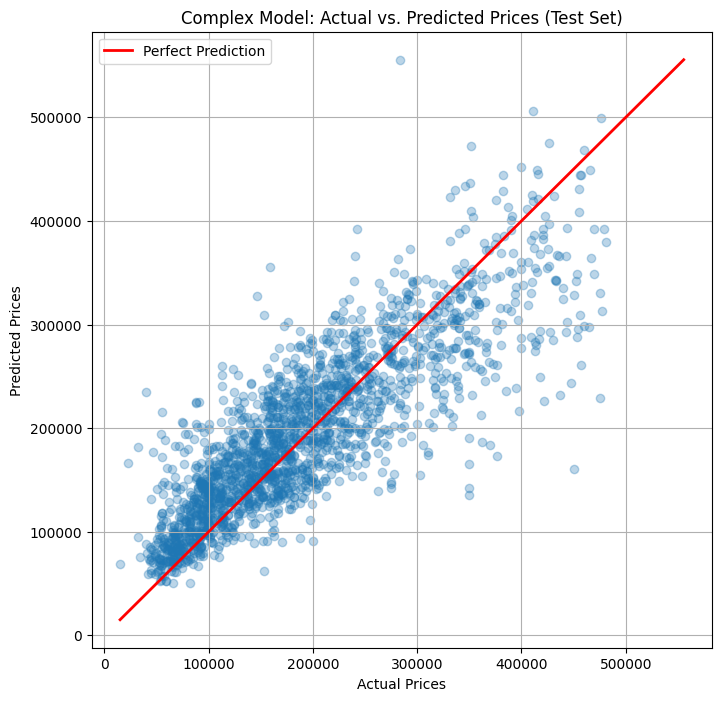

In [25]:

# y_true_test (from y_test.values)
# y_pred_test_c_1d (from model_cmplx.predict)

# Create the 'Actual vs. Predicted' scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(y_true_test, y_pred_test_c_1d, alpha=0.3)

# Add a perfect-prediction line (y=x)
min_val = min(y_true_test.min(), y_pred_test_c_1d.min())
max_val = max(y_true_test.max(), y_pred_test_c_1d.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', lw=2, label='Perfect Prediction')

plt.title('Complex Model: Actual vs. Predicted Prices (Test Set)')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.legend()
plt.grid(True)
plt.show()



The complex model performed better:higher R2 score and the lower MAE/RMSE as proof.

Why it was better:

The simple model was underfitting (it was too simple, with only 89 parameters, to learn the patterns).

The complex model (with 12,289 parameters) was "deeper" and "wider," so it had more power to find complex relationships in the data.

The lower learning rate (0.001 vs. 0.1) helped the complex model train more stably, as seen in the smooth loss plot.
